In [ ]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


## PanGI

In [16]:
pangi  <- readRDS("../../DATA_scRNAseq/Analysis_of_previously_published_data/107_PanGI/PanGI_CD4_integrated.rds")


In [17]:
pangi

An object of class Seurat 
58579 features across 46129 samples within 3 assays 
Active assay: RNA (35461 features, 0 variable features)
 2 layers present: counts, data
 2 other assays present: SCT, integrated
 2 dimensional reductions calculated: pca, umap

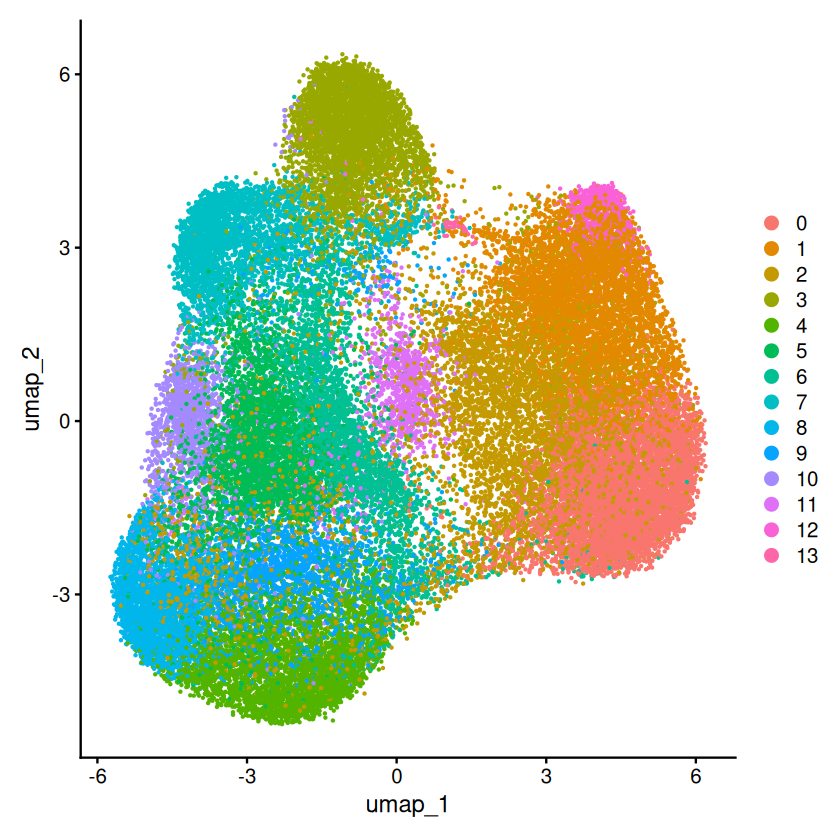

In [4]:
DimPlot(pangi)

In [ ]:
pangi$`integrated_snn_res.0.5`

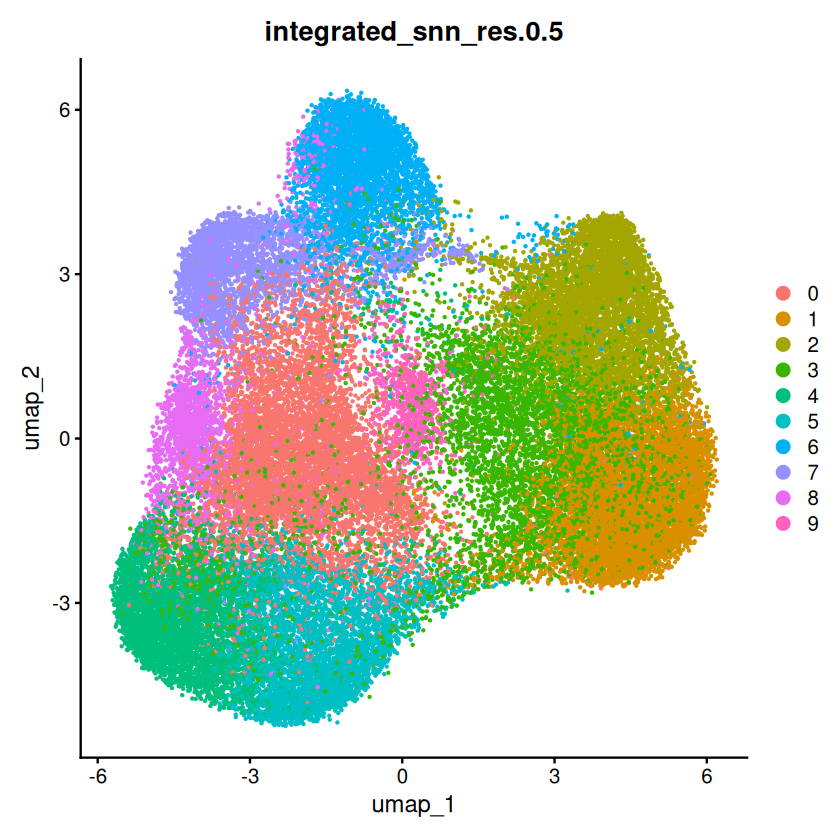

In [5]:
DimPlot(pangi, group.by = "integrated_snn_res.0.5")

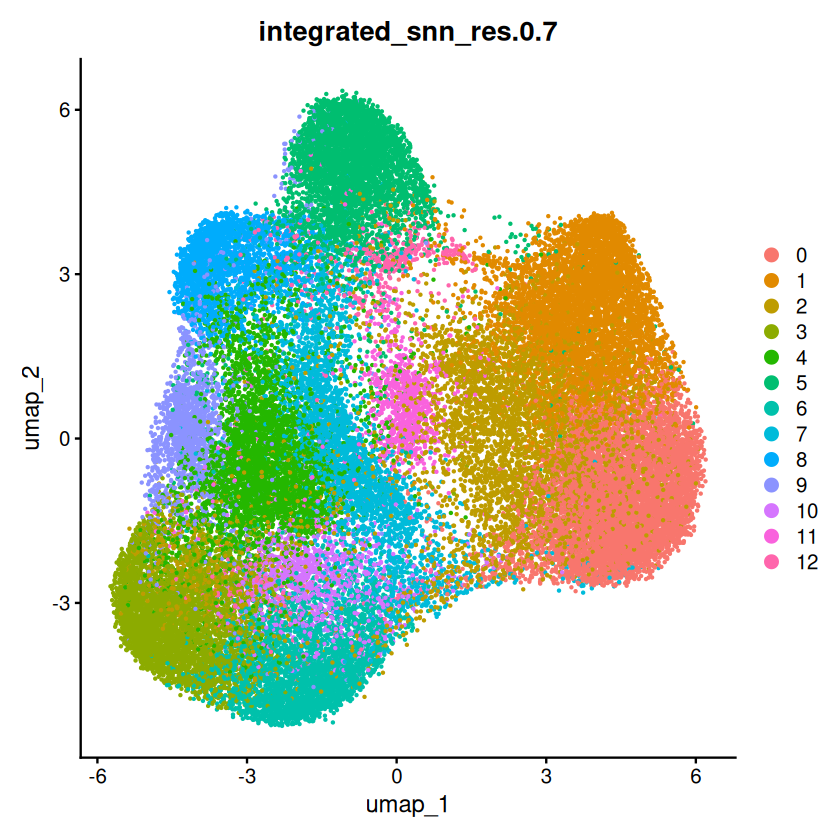

In [6]:
DimPlot(pangi, group.by = "integrated_snn_res.0.7")

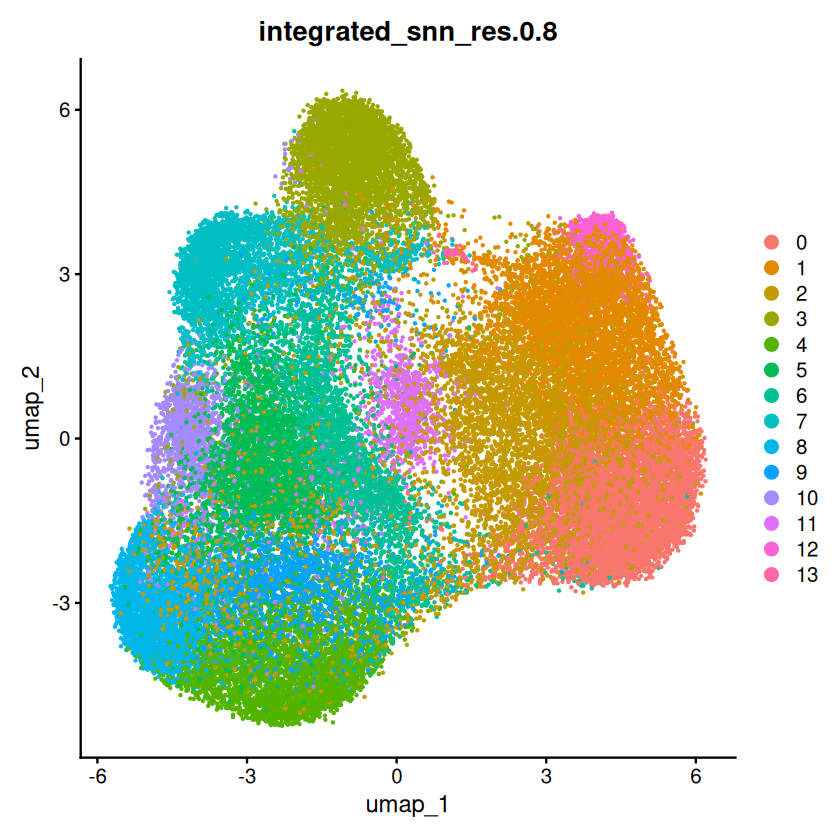

In [7]:
DimPlot(pangi, group.by = "integrated_snn_res.0.8")

In [8]:
pangi$sampleID  %>% table

.
       4861STDY7135911        4861STDY7135912        4861STDY7135913 
                   905                     13                   1291 
       4861STDY7135914        4861STDY7135915        4861STDY7135916 
                    22                    309                      5 
       4861STDY7135917        4861STDY7135918        4861STDY7208410 
                   410                      5                    537 
       4861STDY7208411        4861STDY7208412        4861STDY7208413 
                     3                    399                      5 
       4861STDY7208414        4861STDY7208415        4861STDY7208416 
                   122                      2                    501 
       4861STDY7208417        4918STDY7274839        4918STDY7333456 
                     4                    116                    349 
       4918STDY7389431        4918STDY7447825        4918STDY7702679 
                   105                    328                    172 
       4918STDY784

In [9]:
pangi$donorID_unified  %>% table

.
    D1   D104   D105   D107   D108   D109    D11   D110   D111   D113   D116 
   116   2576   3372    236    273    183    218    233    350    115    128 
   D12   D120   D123   D125   D127   D128    D13   D130   D133   D138    D14 
   300    509    250    240    231    389    171    143    174    720    856 
  D140   D141   D142    D15   D157   D158    D16    D17    D18     D2    D21 
  1478   1733   3203   2327    414    312   2960   1573    556    349    149 
   D22    D28     D3     D4    D41    D42    D43    D44    D45    D46    D47 
   330    835    105    328    383    361    431    315    191    842    264 
   D48    D49     D5    D57    D59     D6    D60    D68    D72     D8    D80 
   319    286    172    118      1    175    116    167    167    119    299 
   D84    D85    D86    D87    D89    D90    D95    D96    D97    D98    D99 
   103    104    369    144   2551   1737    504    755    460    174    248 
Dpool1 Dpool2    F10    F12    F15    F16    F18    F19    F20

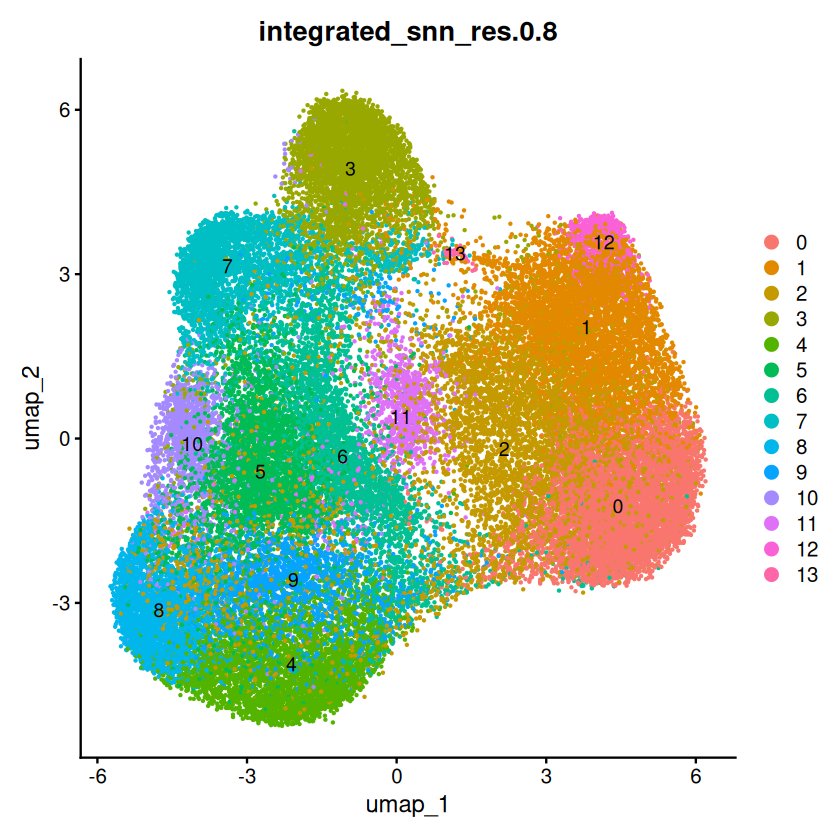

In [11]:
DimPlot(pangi, group.by = "integrated_snn_res.0.8", label = T)

In [14]:
gn2  <- c('GZMA', 'GZMB','GZMH','GNLY', 'IFNG', "PRF1",'CTSH', 
          'HLA-DRB5','FASLG',  'ZEB2',"RORC","TBX21","EOMES","BHLHE40",
          "IL23R",
          'IL12RB2', "CXCR6",
          'IL26', 'IL17A','IL22','CCL4', 'CSF2')


## Marker genes
avgexp3 = AverageExpression(pangi, features = gn2, group.by = "integrated_snn_res.0.8",
                          assay = "RNA")
colnames(avgexp3$RNA)  <- gsub(colnames(avgexp3$RNA), pattern = "g", replacement = "")

dir.create("figures/heatmaps_other_data")

options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 14, filename = "figures/heatmap_pangi.pdf",
                  width = 5, height = 7)

options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white")

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `integrated_snn_res.0.8` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.


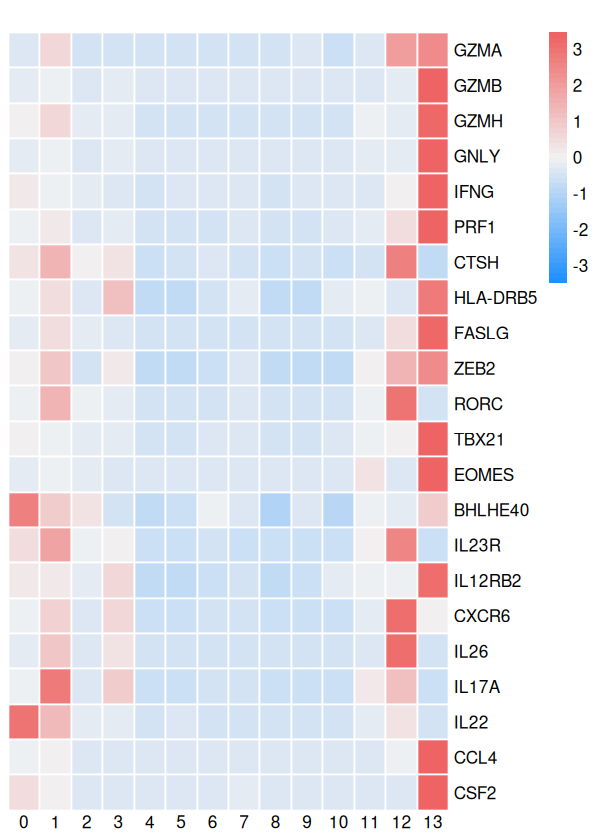

In [17]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white")

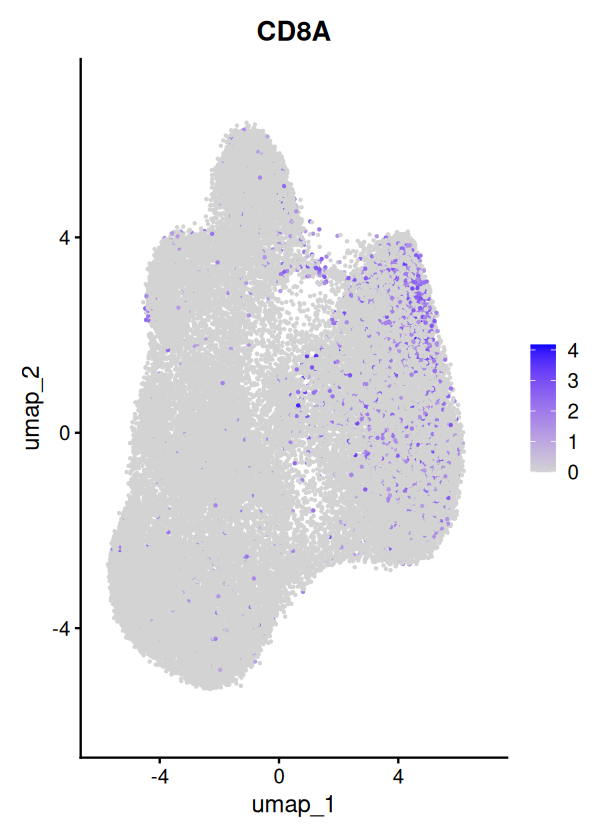

In [18]:
FeaturePlot(pangi, features = "CD8A", min.cutoff = 0)

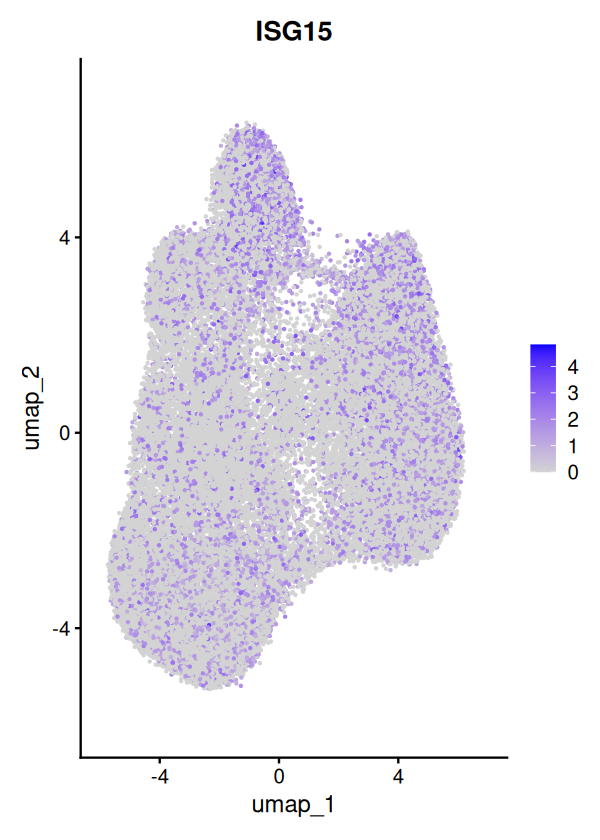

In [19]:
FeaturePlot(pangi, features = "ISG15", min.cutoff = 0)

In [50]:
options(repr.plot.width = 6, repr.plot.height = 4.5)


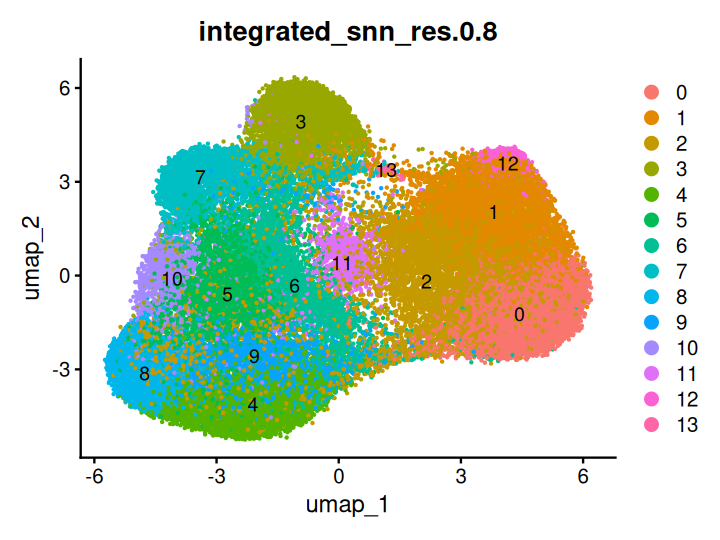

In [51]:
DimPlot(pangi, group.by = "integrated_snn_res.0.8", label = T)

In [35]:
ls()

[1] "avgexp3"          "bl_3p"            "bl_5p"            "ggtheme"         
[5] "gn2"              "pallete_blood_5p" "pangi"

In [37]:
pangi$cd4_ctl  <- ifelse(pangi$seurat_clusters == 12, "CTL","Other")
pangi$cd4_ctl  %>% table


.
  CTL Other 
  818 45311 

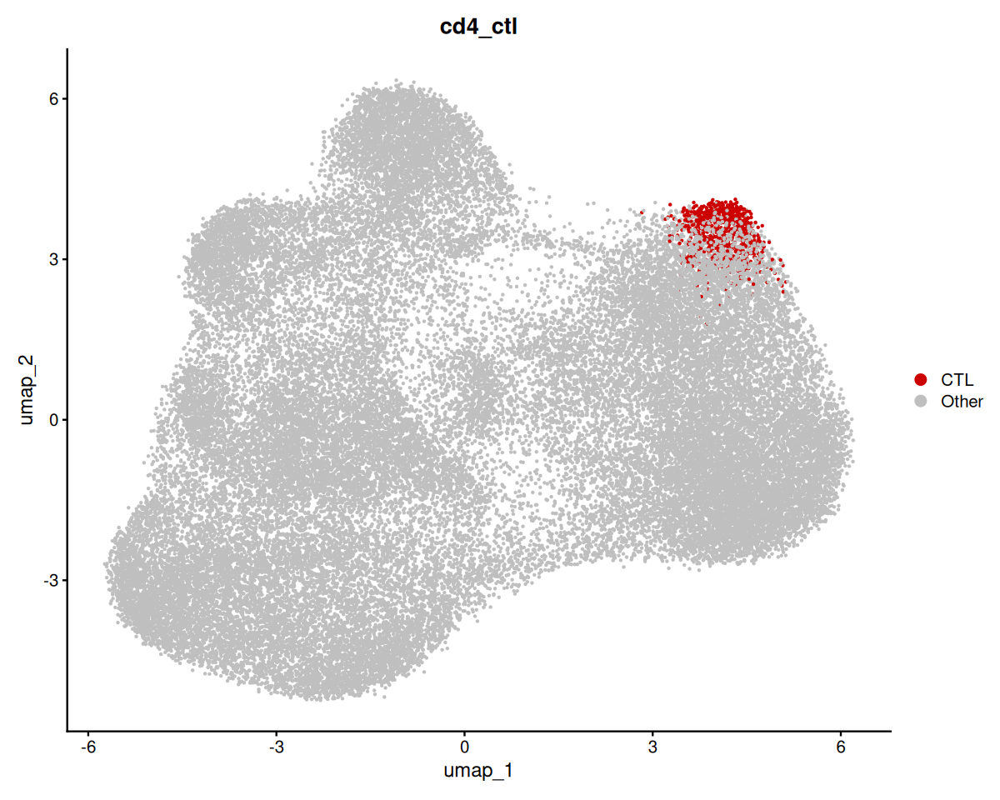

In [38]:
options(repr.plot.width = 10, repr.plot.height = 8)
DimPlot(pangi, group.by = "cd4_ctl", cols = c("#cd0000ff","grey75"))

In [39]:
cd4_ctl_sig  <- c(

    'GZMA', 'CTSH', 'IFNG', 'CCL4', 'HLA-DRB5', 'ZEB2', 'CHN1', 'IL12RB2', 'TESC', 'ADAM12', 'CPNE7', 'IL26',
    'GZMH', 'DAPK2', 'GZMB', 'COL5A3', 'OASL', 'NCR3', 'MCOLN2', 'GNLY', 'CSF2', 'MSC', 'GOLIM4', 
    'LINC02694', 'IL17A', 'GZMK', 'CDCA7', 'LINC00299', 'GPR34', 'LINC02384', 'FASLG', 'IL22', 'PKIG', 
    'APOBEC3H', 'PPARG', 'NUSAP1', 'SLC27A2', 'MSC-AS1', 'LYN', 'NTRK2', 'HDGFL3', 'MREG', 'MKI67', 
    'HLA-DQA2', 'KLRD1', 'SLAMF8', 'FSD1', 'TMPRSS3', 'PCLAF', 'TYMS', 'TOP2A', 'SETBP1', 'TOGARAM2', 'TPX2', 
    'IL17F', 'AL139393.3', 'PROK2', 'RHOU', 'MYO7A', 'EOMES', 'CENPE', 'TK1', 'KIF11', 'NCAPH', 'FCRL6', 'TIAM2', 
    'RRM2', 'CDK1', 'CDT1', 'RCAN2', 'SYNGR3', 'PALLD', 'BIRC5', 'ASPM', 'C3orf14', 'WWTR1', 'PLEKHG3', 'OTUB2', 
    'FES', 'ELOVL4', 'ADGRG5', 'CCNA2', 'UBE2C', 'EVC', 'KIFC1', 'TNS3', 'CD160', 'CCNB2', 'KIF23', 'AC243829.4', 
    'NCAPG', 'DOCK5', 'KIF2C', 'AC092580.4', 'P4HA2', 'CDCA2', 'PKMYT1', 'UHRF1', 'GTSE1', 'GPR27', 'DPF3', 
    'LINC02446', 'DLGAP5', 'ZNF683', 'CDC20', 'TROAP', 'AURKB', 'CEND1', 'CENPA', 'NMU', 'BUB1B', 'MELK', 'FOXM1', 
    'DEPDC1B', 'HMMR', 'CDCA5', 'CKAP2L', 'SHCBP1', 'RGS9', 'KIF14', 'KIF15', 'CDCA3', 'RAD51', 'PLK1', 'SPC25', 
    'CCR1', 'KIF4A', 'HJURP', 'NUGGC', 'PRR11', 'ESCO2', 'CDC45', 'MND1', 'TENM4', 'PIF1', 'HRH4', 'TP73', 'ADGRG1', 
    'PXDC1', 'SPC24', 'DIAPH3', 'E2F2', 'ANLN', 'MCM10', 'ATP8B4', 'SKA1', 'AL139393.2', 'DEPDC1', 'E2F8', 'SKA3', 
    'PDLIM4', 'GLDC', 'PBK', 'NCS1', 'KIF20A', 'TP63', 'CES1', 'KIF18B', 'HIST1H3G', 'KLHL13', 'HIST1H3C', 'BATF3', 
    'SOX5', 'E2F7', 'ARNTL2', 'CDC25A', 'ZBED2', 'MPPED2', 'FAM111B', 'GLB1L2', 'AL133405.2', 'NTRK1', 'FAM72B', 
    'TRPC3', 'AL356234.2', 'HMHB1', 'AC013460.1', 'CDC25C', 'KRT86', 'KLRC4', 'TYMSOS', 'KLRC1', 'ESPL1', 'ODAPH', 
    'RASGEF1A', 'PKHD1', 'KLRC2'
)

In [40]:
DefaultAssay(pangi)  <- "RNA"
cd4_ctl_sig_filt  <- cd4_ctl_sig[which(cd4_ctl_sig %in% rownames(pangi@assays$RNA))]
pangi  <- AddModuleScore(pangi, features = list(cd4_ctl_sig),
  name     = "CTL_score")

Warning message:
“The following features are not present in the object: LINC00299, LINC02384, HLA-DQA2, AL139393.3, C3orf14, AC243829.4, AC092580.4, AL139393.2, HIST1H3G, HIST1H3C, ARNTL2, AL133405.2, AL356234.2, AC013460.1, TYMSOS, not searching for symbol synonyms”


In [41]:
pangi_umap  <- pangi@reductions$umap@cell.embeddings
pangi$UMAP_1  <- pangi_umap[,1]
pangi$UMAP_2  <- pangi_umap[,2]

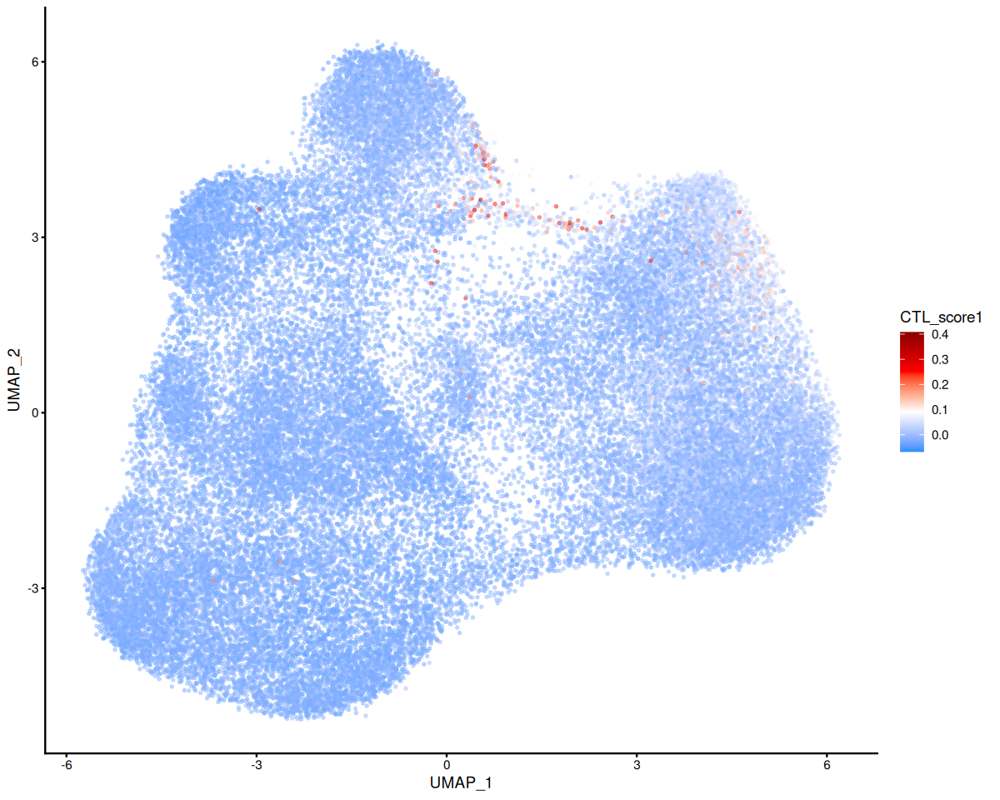

In [42]:
options(repr.plot.width = 10, repr.plot.height = 8)
pangi@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","darkred"),
    #rescaler = ~ scales::rescale_mid(.x, mid = 0)
  )

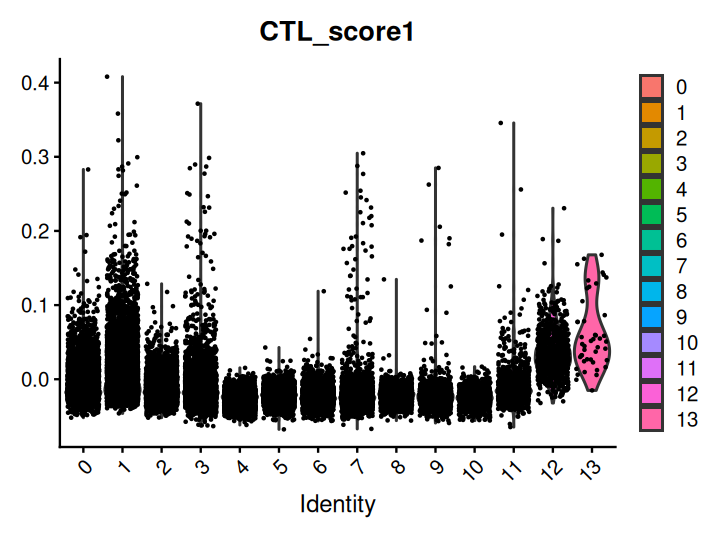

In [52]:
VlnPlot(pangi, features = "CTL_score1")

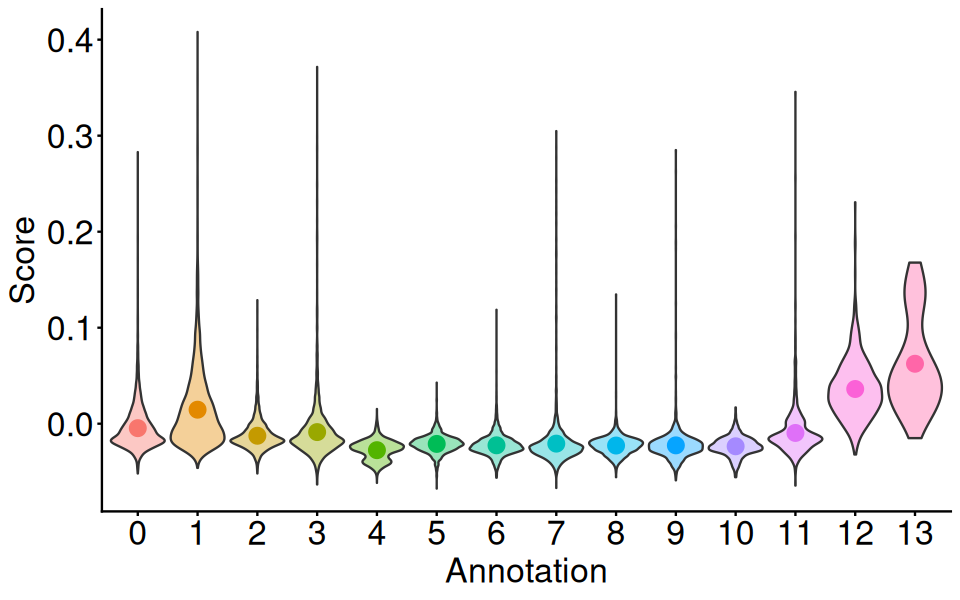

In [115]:
ggplot(data.frame(Score = pangi$CTL_score1,
                  Annotation = pangi$seurat_clusters), 
       aes(x = Annotation, y = Score)) +
  geom_violin(scale = "width", aes(fill = Annotation), alpha = 0.4) + 
  stat_summary(fun = "mean",
               geom = "point", 
               size = 4,
               aes(colour = Annotation)) +
theme_classic() +
ggtheme() + NoLegend()

In [116]:
ggsave(filename = "figures/vlnplot_pangi.svg",
                  width = 14, height = 10, units = "cm")

In [68]:
pangi@meta.data  %>% group_by(sampleID)  %>% tally()  %>% arrange((n))

sampleID,n
<chr>,<int>
ERR4161429,1
ERR4161480,1
FCA_gut8015059,1
FCA_gut8015060,1
Human_colon_16S7255680,1
Human_colon_16S8000473,1
Human_colon_16S8001879,1
Human_colon_16S8002581,1
Human_colon_16S8002630,1


In [69]:
samples_keep  <- pangi@meta.data  %>% group_by(sampleID)  %>% tally()  %>% arrange((n))  %>% 
dplyr::filter(n>19)  %>% pull(sampleID)

In [70]:
pangi$tissue  %>% table

.
                  ascending colon                   body of stomach 
                               95                              1811 
                    buccal mucosa                            caecum 
                              437                              1688 
                            colon                colonic epithelium 
                             3158                              2279 
                   colonic mucosa                  descending colon 
                             1893                                43 
              duodenal epithelium                          duodenum 
                              157                              1492 
          epithelium of esophagus     epithelium of small intestine 
                              235                               364 
            epithelium of stomach                         esophagus 
                              221                                 8 
                          gingiv

In [71]:
pangi$tissue_fraction  %>% table

.
    Epithelium Full_thickness Lamina_propria         Mucosa 
          3498          18360           8839          15432 

In [74]:
pangi@meta.data  %>% 
dplyr::filter(sampleID %in% samples_keep) %>% 
group_by(sampleID, tissue)  %>% tally()  %>% arrange((n))

sampleID,tissue,n
<chr>,<chr>,<int>
Human_colon_16S7985390,ileum,20
4861STDY7135914,mesenteric lymph node,22
Human_colon_16S8159184,ileum,22
Pan_T7935488,transverse colon,23
Human_colon_16S8123912,ileum,25
Human_colon_16S7985389,ileum,30
Human_colon_16S8002626,ascending colon,30
Pan_T7935490,ileum,32
Human_colon_16S7985392,colon,33


In [87]:
pangi@meta.data  %>% 
dplyr::filter(sampleID %in% samples_keep) %>% 
group_by(tissue, sampleID)  %>% tally() %>% 
ungroup %>% 
group_by(tissue)  %>% 
tally()  %>% 
arrange(n)


tissue,n
<chr>,<int>
duodenal epithelium,1
epithelium of small intestine,1
epithelium of stomach,1
ileal epithelium,1
intestine,1
lamina propria of small intestine,1
parotid gland,1
rectum,1
vermiform appendix,1


In [89]:
tissues_keep   <- pangi@meta.data  %>% 
dplyr::filter(sampleID %in% samples_keep) %>% 
group_by(tissue, sampleID)  %>% tally() %>% 
ungroup %>% 
group_by(tissue)  %>% 
tally()  %>% 
dplyr::filter(n>2)  %>% pull(tissue)

In [90]:
md <- pangi@meta.data
df4 <- md %>% 
dplyr::filter(sampleID %in% samples_keep & tissue %in% tissues_keep) %>% 
group_by(sampleID, seurat_clusters)  %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sampleID, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(tissue, tissue_fraction, 
                                   sampleID) %>% unique()
df4  <- left_join(df4, md_to_join, by = "sampleID")


`summarise()` has grouped output by 'sampleID'. You can override using the
`.groups` argument.


In [78]:
df4

sampleID,seurat_clusters,freq,tissue,tissue_fraction
<chr>,<chr>,<dbl>,<chr>,<chr>
4861STDY7135911,0,0.4508287293,caecum,Full_thickness
4861STDY7135911,1,0.0530386740,caecum,Full_thickness
4861STDY7135911,2,0.0685082873,caecum,Full_thickness
4861STDY7135911,3,0.0541436464,caecum,Full_thickness
4861STDY7135911,4,0.0519337017,caecum,Full_thickness
4861STDY7135911,5,0.1591160221,caecum,Full_thickness
4861STDY7135911,6,0.0696132597,caecum,Full_thickness
4861STDY7135911,7,0.0099447514,caecum,Full_thickness
4861STDY7135911,8,0.0309392265,caecum,Full_thickness


Warning message in geom_boxplot(alpha = 0.3, aes(fill = tissue), scale = "width", :
“Ignoring unknown parameters: `scale`”
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


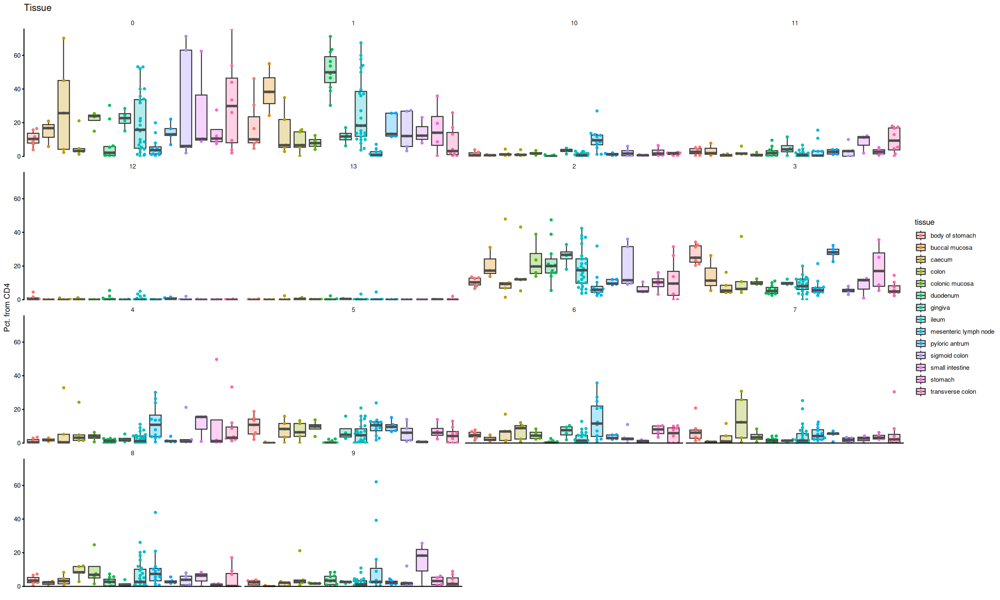

In [91]:
options(repr.plot.width = 20, repr.plot.height = 12)
df4  %>% 
ggplot(aes(x = tissue, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_boxplot(alpha = 0.3, aes(fill = tissue), scale = "width", outlier.shape = NA) + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = tissue), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Tissue")



Warning message in geom_boxplot(alpha = 0.3, aes(fill = tissue), scale = "width", :
“Ignoring unknown parameters: `scale`”
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


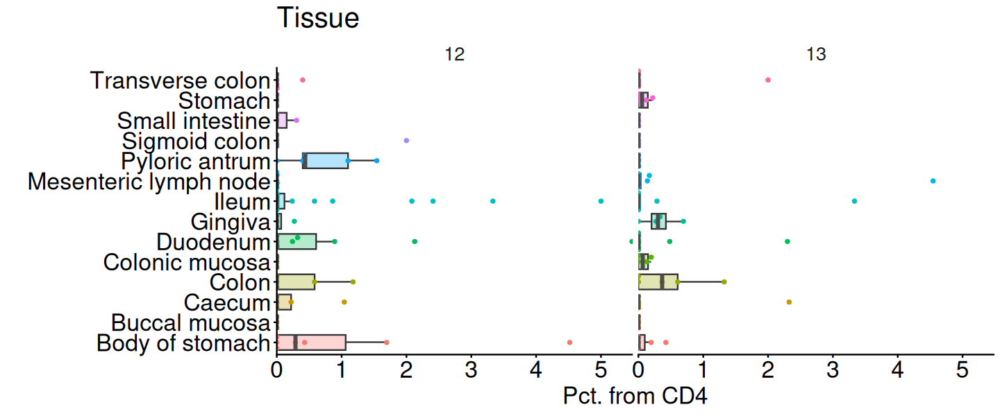

In [124]:
options(repr.plot.width = 12, repr.plot.height = 5)
df4  %>% 
mutate(tissue = str_to_sentence(tissue))  %>% 
dplyr::filter(seurat_clusters %in% c(12,13)) %>% 
ggplot(aes(x = tissue, y = freq*100)) + 
   geom_boxplot(alpha = 0.3, aes(fill = tissue), scale = "width", outlier.shape = NA) + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = tissue), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank()) + ggtitle(label = "Tissue") +
ggtheme() +
coord_flip() +
NoLegend()


In [125]:
ggsave(filename = "figures/boxplot_pangi_freq_in_samples.svg",
                  width = 16, height = 14, units = "cm")

In [109]:
pal  <- scales::hue_pal()(14)
names(pal)  <- c(0:13)

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


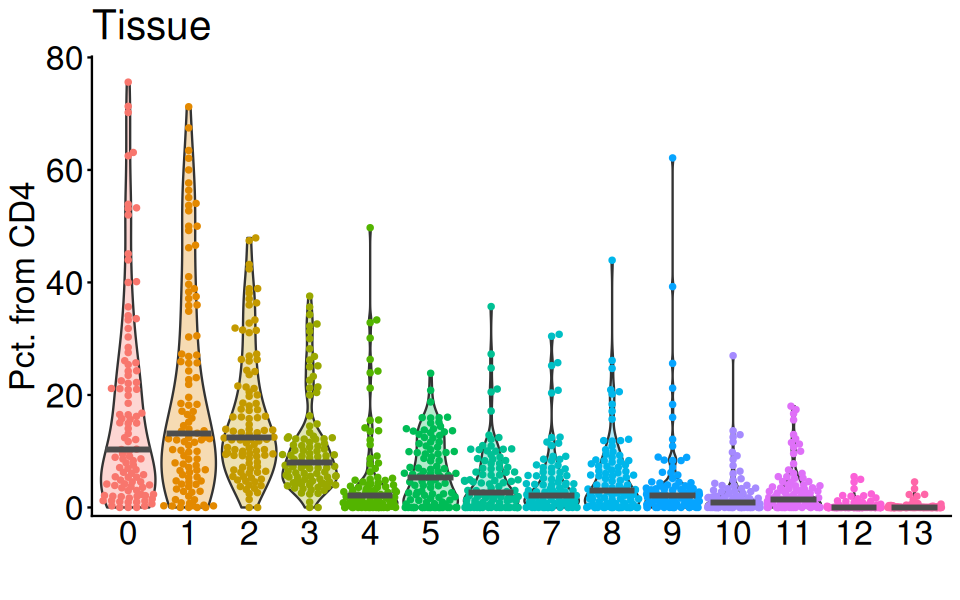

In [110]:
options(repr.plot.width = 8, repr.plot.height = 5)
df4  %>% 
ggplot(aes(x = factor(seurat_clusters, levels = c(0:13)),
                      y = freq*100)) + # you can change the x to whatever variable you're interested in
 geom_violin(alpha = 0.3, aes(fill = seurat_clusters), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = seurat_clusters), cex = 1, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  scale_y_continuous(limits = c(0,NA), expand = expansion(mult = c(0.02, 0.06)))+
       theme_classic() +
scale_fill_manual(values = pal) +
scale_color_manual(values = pal) +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank()) + ggtitle(label = "Tissue") +
ggtheme() + NoLegend()

In [113]:
ggsave(filename = "figures/vlnplot_pangi_freq_in_samples.svg",
                  width = 17, height = 10, units = "cm")

In [157]:
ls()

[1] "avgexp3"          "bl_3p"            "bl_5p"            "cd4_ctl_sig"     
 [5] "cd4_ctl_sig_filt" "df4"              "ggtheme"          "gn2"             
 [9] "md"               "md_to_join"       "pal"              "pallete_blood_5p"
[13] "pangi"            "pangi_umap"       "samples_keep"     "tissues_keep"

## scIBD

In [4]:
scibd  <- readRDS("../../DATA_scRNAseq/Analysis_of_previously_published_data/108_SC_IBD/scIBD_CD4_integrated.rds")


In [66]:
cd4_integrated$participant_id  %>% table  %>% length

[1] 138

In [67]:
cd4_integrated$participant_id2  <- gsub(cd4_integrated$participant_id, pattern = "p", replacement = "001-")

In [68]:
cd4_integrated$participant_id2  %>% table  %>% length

[1] 106

In [70]:
cd4_integrated


An object of class Seurat 
45570 features across 513115 samples within 2 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

In [64]:
options(repr.plot.width = 10, repr.plot.height = 8)
DimPlot(scibd)

ERROR: Error in eval(expr, envir, enclos): object 'scibd' not found


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



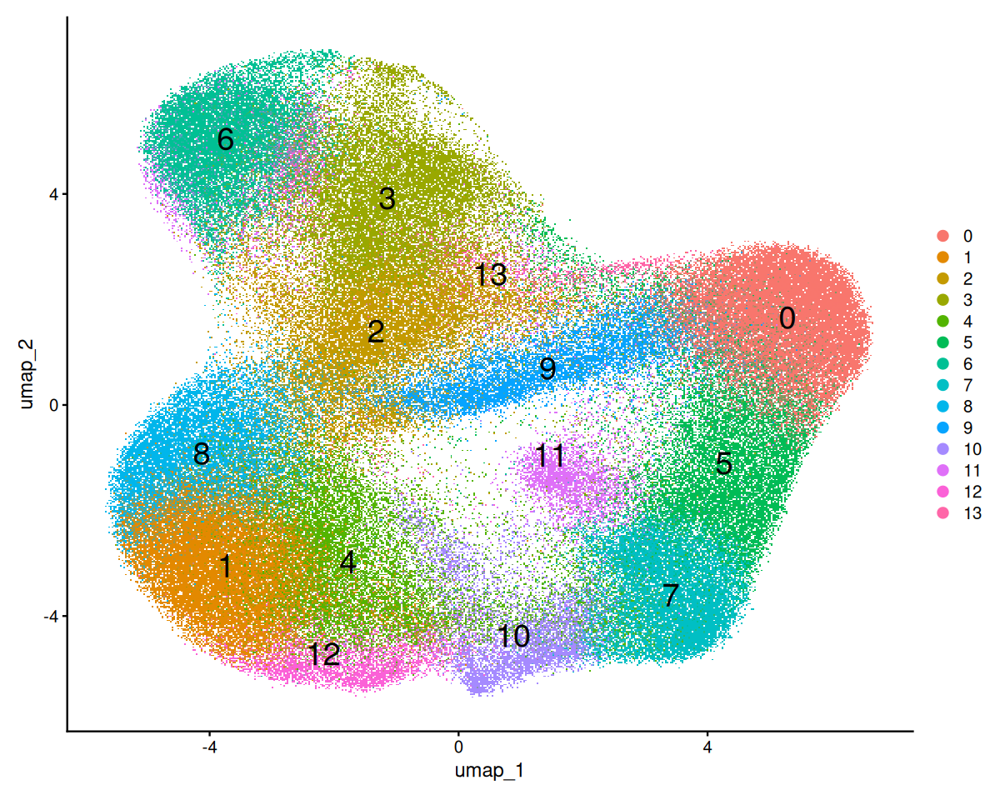

In [10]:
DimPlot(scibd, label = T, label.size = 8)

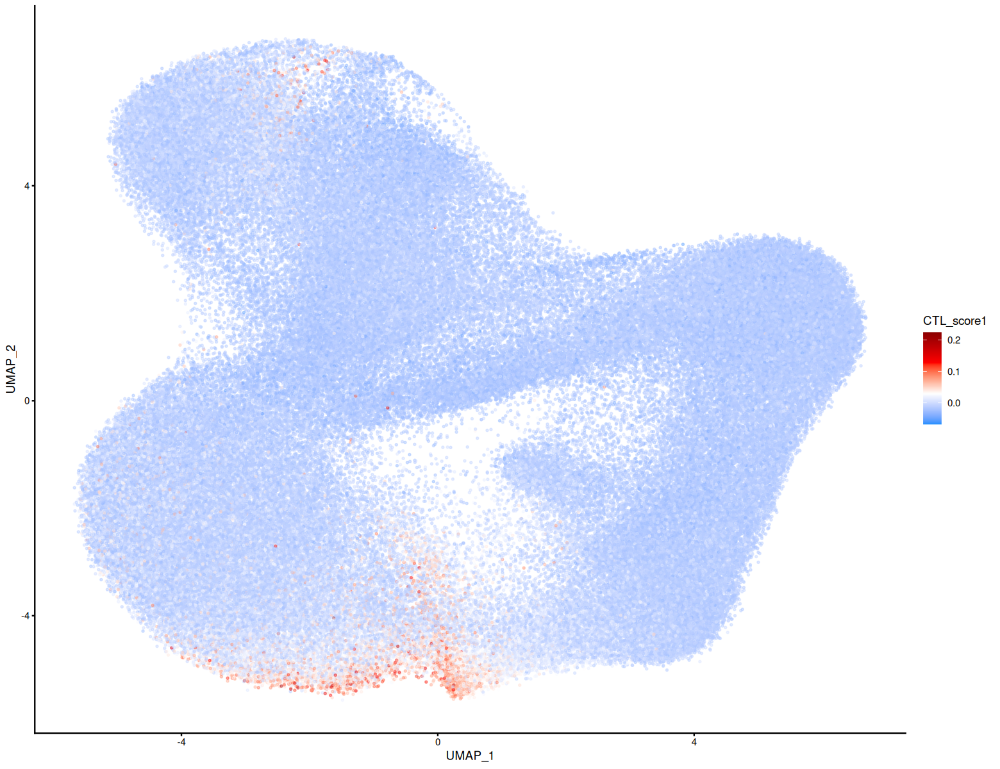

In [6]:
scibd$UMAP_1 <- Embeddings(scibd, reduction = "umap")[, 1]
scibd$UMAP_2 <- Embeddings(scibd, reduction = "umap")[, 2]

options(repr.plot.width = 13, repr.plot.height = 10)
scibd@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","darkred"))

In [62]:
scibd

ERROR: Error in eval(expr, envir, enclos): object 'scibd' not found


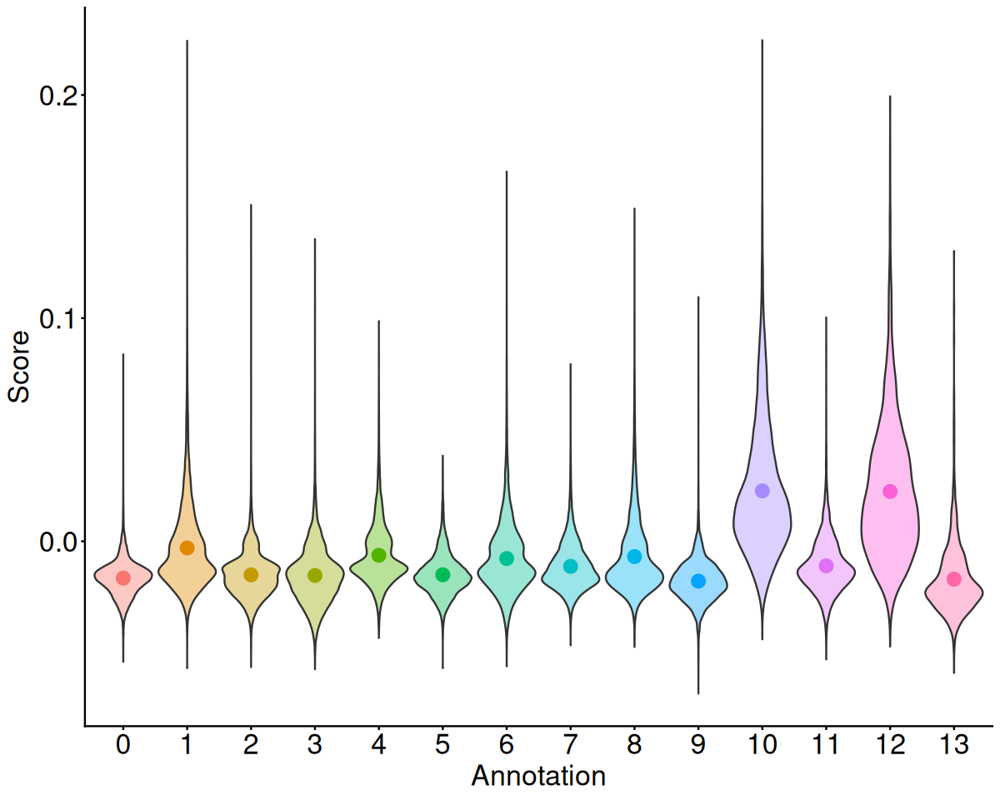

In [11]:
ggplot(data.frame(Score = scibd$CTL_score1,
                  Annotation = scibd$seurat_clusters), 
       aes(x = Annotation, y = Score)) +
  geom_violin(scale = "width", aes(fill = Annotation), alpha = 0.4) + 
  stat_summary(fun = "mean",
               geom = "point", 
               size = 4,
               aes(colour = Annotation)) +
theme_classic() +
ggtheme() + NoLegend()

In [12]:
ggsave(filename = "figures/vlnplot_scibd.svg",
                  width = 14, height = 10, units = "cm")

In [13]:
gn2  <- c('GZMA', 'GZMB','GZMH','GNLY', 'IFNG', "PRF1",'CTSH', 
          'HLA-DRB5','FASLG',  'ZEB2',"RORC","TBX21","EOMES","BHLHE40",
          "IL23R",
          'IL12RB2', "CXCR6",
          'IL26', 'IL17A','IL22','CCL4', 'CSF2')


## Marker genes
avgexp3 = AverageExpression(scibd, features = gn2, group.by = "integrated_snn_res.0.8",
                          assay = "RNA")
colnames(avgexp3$RNA)  <- gsub(colnames(avgexp3$RNA), pattern = "g", replacement = "")

dir.create("figures/heatmaps_other_data")

options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 14, filename = "figures/heatmap_scibd.pdf",
                  width = 5, height = 7)

options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white")

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `integrated_snn_res.0.8` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.
Warning message in dir.create("figures/heatmaps_other_data"):
“'figures/heatmaps_other_data' already exists”


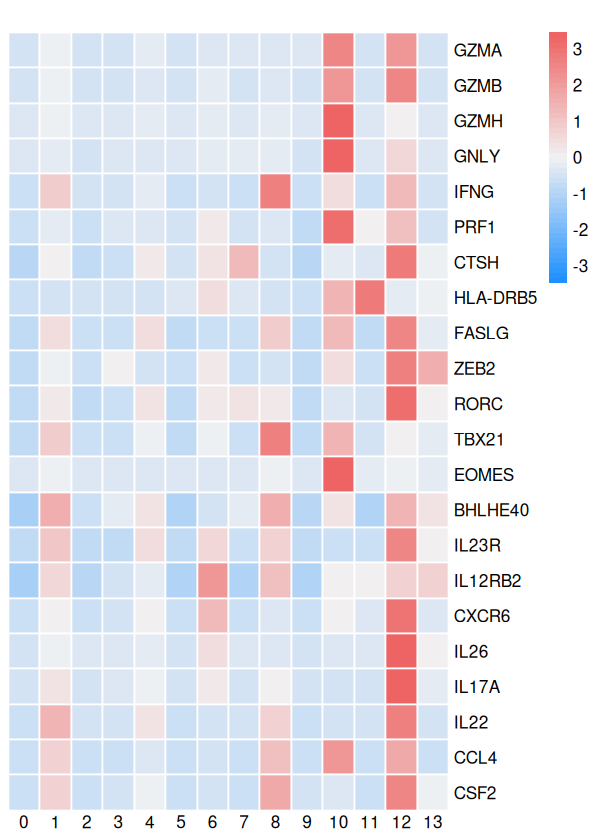

In [14]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white")

In [22]:
meta_data  %>% group_by(sample, subject, tissue.sub)  %>% tally()

sample,subject,tissue.sub,n
<chr>,<chr>,<chr>,<int>
4918STDY7273964,T017,ileum,715
4918STDY7273965,T019,ileum,372
4918STDY7333456,T036,ileum,444
4918STDY7389431,T044,ileum,103
4918STDY7447825,T057,ileum,355
4918STDY7702679,T110NEG,ileum,210
4918STDY7844898,T160,ileum,218
4918STDY7844899,T161,ileum,124
4918STDY7901096,T176,ileum,963


In [30]:
meta_data <- scibd@meta.data

# Create grouped dataframe, calculate the frequencies of clusters
df4 <- meta_data %>% 
  group_by(sample, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>% 
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sample, names_to = "seurat_clusters", values_to = "freq")


`summarise()` has grouped output by 'sample'. You can override using the
`.groups` argument.


In [31]:
# As we've lost non-grouping variables, let's join them back
md_to_join <- meta_data %>% 
dplyr::select(sample, subject, tissue.sub, tissue, disease) %>% 
  unique()

df4  <- left_join(df4, md_to_join)


Joining with `by = join_by(sample)`


Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


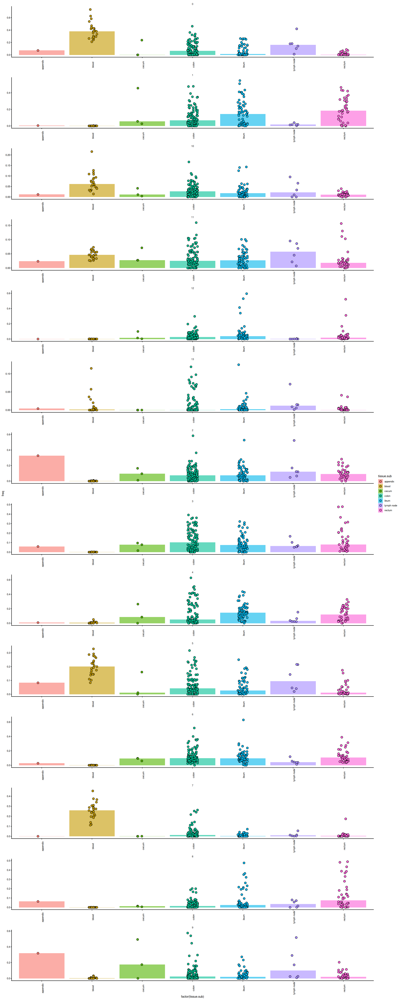

In [32]:
options(repr.plot.width = 20, repr.plot.height = 50)
df4 %>% 
unique  %>% 
  ggplot(aes(x = factor(tissue.sub), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = tissue.sub)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = tissue.sub), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))

In [33]:
PBMC <- df4 %>% dplyr::filter(tissue.sub == "blood")
PBMC_cl10 <- PBMC %>% dplyr::filter(seurat_clusters == "10")
PBMC_cl12 <- PBMC %>% dplyr::filter(seurat_clusters == "12")
ileum <- df4 %>% dplyr::filter(tissue.sub == "ileum")
ileum_cl10 <- ileum %>% dplyr::filter(seurat_clusters == "10")
ileum_cl12 <- ileum %>% dplyr::filter(seurat_clusters == "12")
colon <- df4 %>% dplyr::filter(tissue.sub == "colon")
colon_cl10 <- colon %>% dplyr::filter(seurat_clusters == "10")
colon_cl12 <- colon %>% dplyr::filter(seurat_clusters == "12")

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


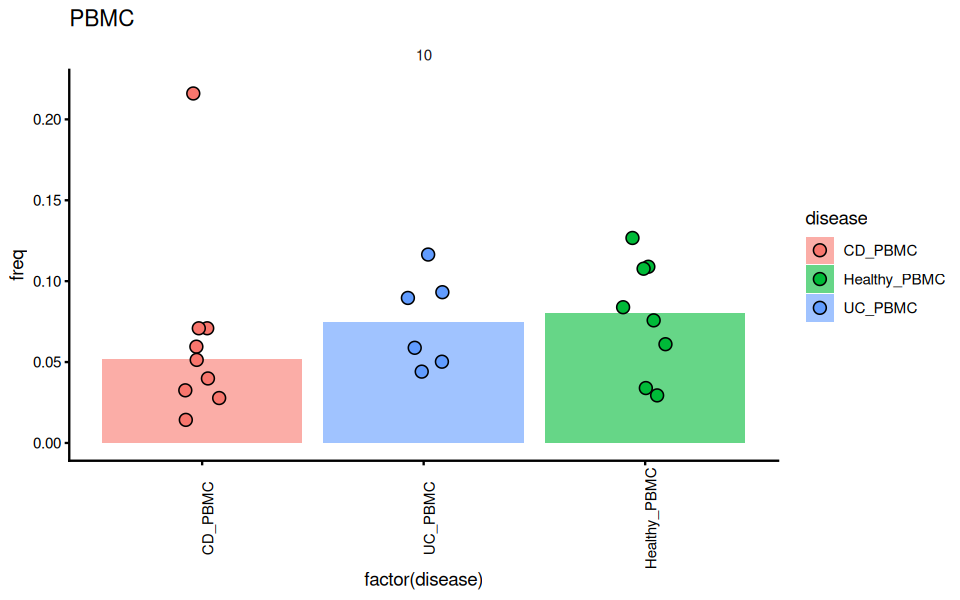

In [34]:
options(repr.plot.width = 8, repr.plot.height = 5)
PBMC_cl10 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("PBMC")+
scale_x_discrete(limits=c("CD_PBMC","UC_PBMC","Healthy_PBMC"))

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


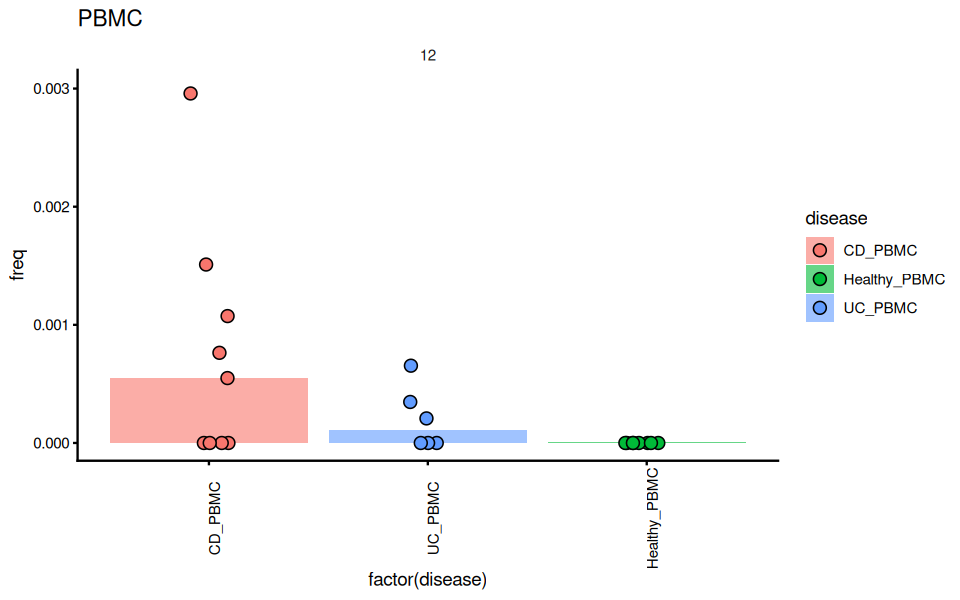

In [35]:
options(repr.plot.width = 8, repr.plot.height = 5)
PBMC_cl12 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("PBMC")+
scale_x_discrete(limits=c("CD_PBMC","UC_PBMC","Healthy_PBMC"))

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


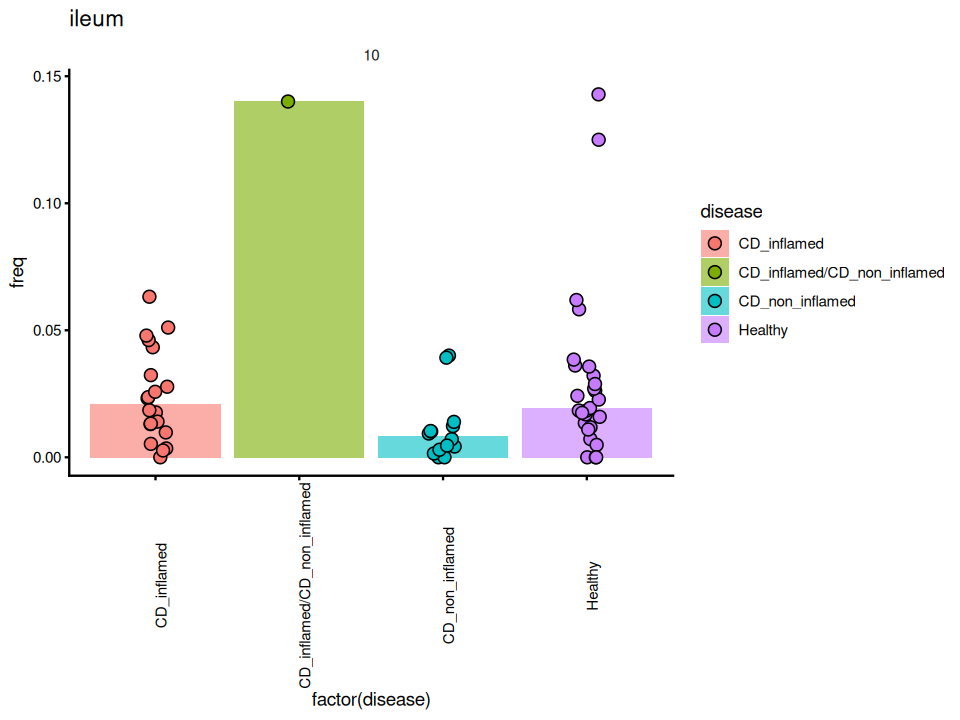

In [36]:
options(repr.plot.width = 8, repr.plot.height = 6)
ileum_cl10 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("ileum")

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


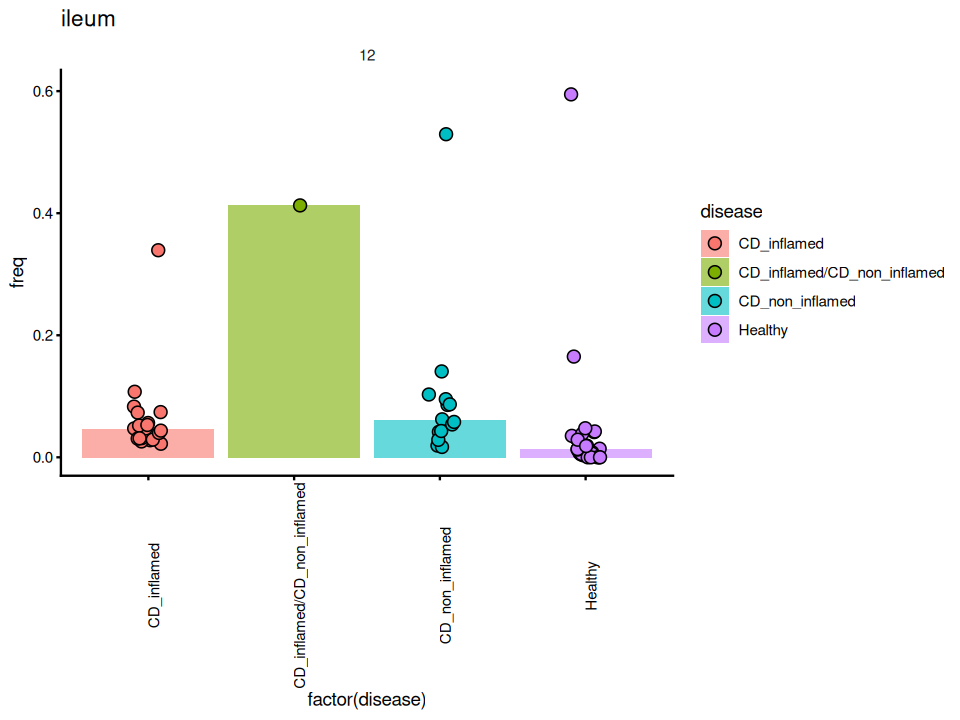

In [37]:
options(repr.plot.width = 8, repr.plot.height = 6)
ileum_cl12 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("ileum")

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


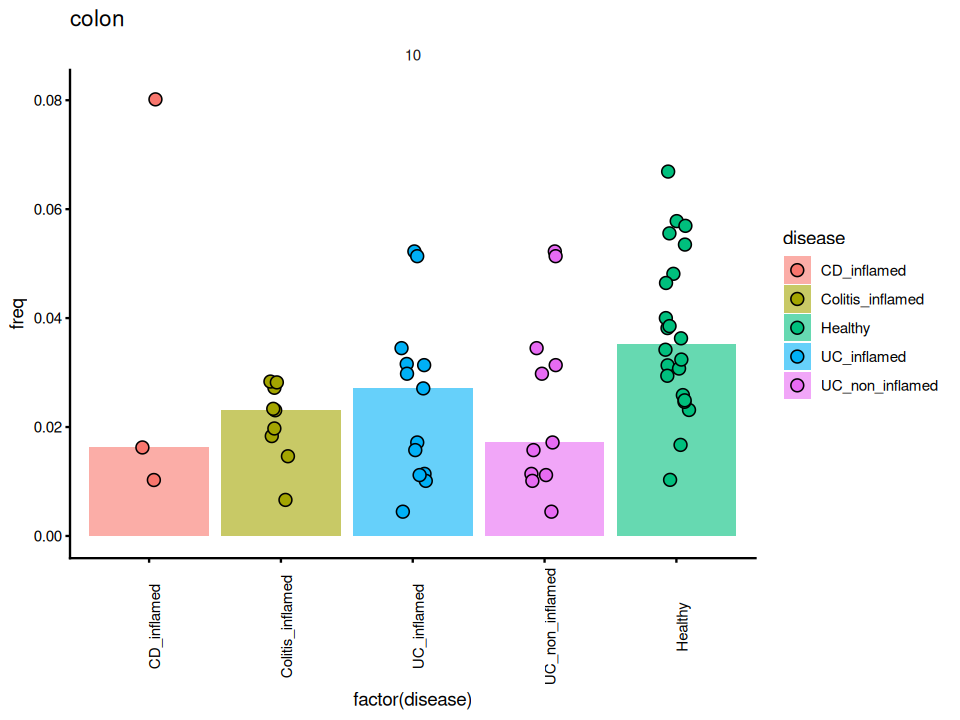

In [96]:
options(repr.plot.width = 8, repr.plot.height = 6)
colon_cl10 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("colon")+
scale_x_discrete(limits=c("CD_inflamed","Colitis_inflamed","UC_inflamed", "UC_non_inflamed", "Healthy"))

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


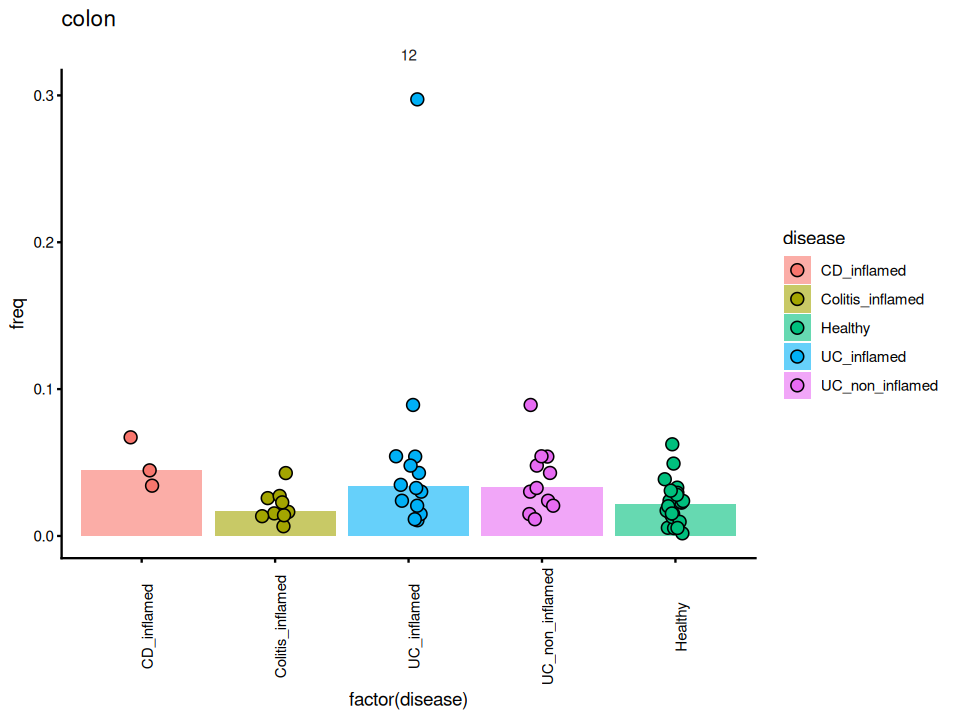

In [98]:
options(repr.plot.width = 8, repr.plot.height = 6)
colon_cl12 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("colon")+
scale_x_discrete(limits=c("CD_inflamed","Colitis_inflamed","UC_inflamed", "UC_non_inflamed", "Healthy"))

### Filter out samples with < 20 cells

In [39]:
meta_data  %>% group_by(sample)  %>% tally()  %>% arrange(n)

sample,n
<chr>,<int>
GSM3584930,11
HRX024334,12
Human_colon_16S8123918,12
GSM3433582,13
N14.EpiA,14
N15.EpiB,15
FCA_gut8015058,16
N11.LPA,16
Human_colon_16S8159190,18


In [41]:
samples_keep  <- meta_data  %>% group_by(sample)  %>% tally()  %>% dplyr::filter(n>19)  %>% pull(sample)

In [42]:
PBMC <- df4 %>% dplyr::filter(tissue.sub == "blood" & sample %in% samples_keep)
PBMC_cl10 <- PBMC %>% dplyr::filter(seurat_clusters == "10")
PBMC_cl12 <- PBMC %>% dplyr::filter(seurat_clusters == "12")
ileum <- df4 %>% dplyr::filter(tissue.sub == "ileum" & sample %in% samples_keep)
ileum_cl10 <- ileum %>% dplyr::filter(seurat_clusters == "10")
ileum_cl12 <- ileum %>% dplyr::filter(seurat_clusters == "12")
colon <- df4 %>% dplyr::filter(tissue.sub == "colon" & sample %in% samples_keep)
colon_cl10 <- colon %>% dplyr::filter(seurat_clusters == "10")
colon_cl12 <- colon %>% dplyr::filter(seurat_clusters == "12")

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.
Warning message:
“Computation failed in `stat_compare_means()`.
Caused by error in `mutate()`:
ℹ In argument: `p = purrr::map(...)`.
Caused by error in `purrr::map()`:
ℹ In index: 1.
ℹ With name: x.3.
Caused by error in `kruskal.test.default()`:
! all observations are in the same group”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.
Warning message:
“Computation failed in `stat_compare_means()`.
Caused by error in `mutate()`:
ℹ In argument: `p = purrr::map(...)`.
Caused by error in `purrr::map()`:
ℹ In index: 1.
ℹ With name: x.3.
Caused by error in `kruskal.test.default()`:
! all observations are in the same group”


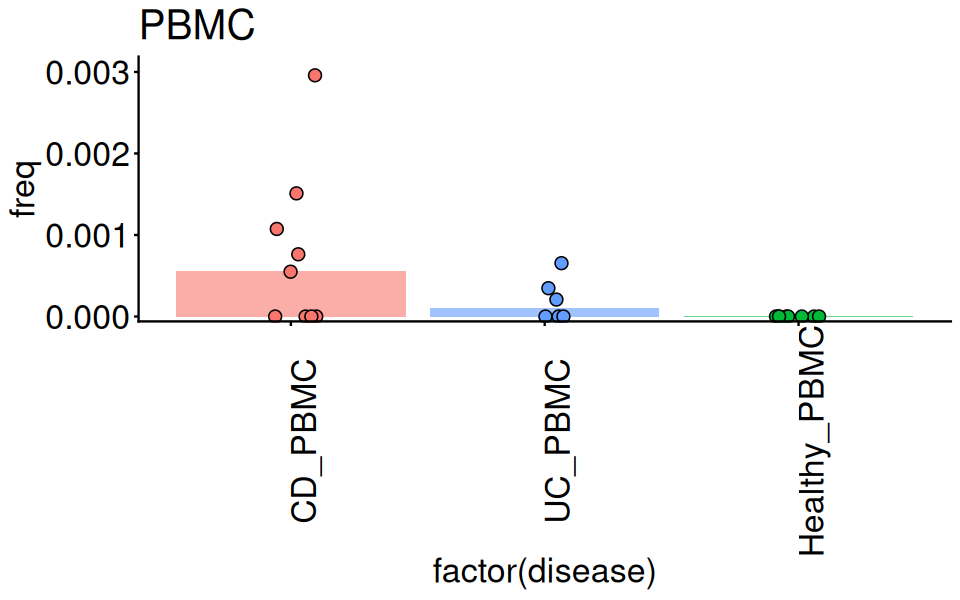

In [87]:
options(repr.plot.width = 8, repr.plot.height = 5)
PBMC_cl12 %>% 
unique  %>% 
ungroup  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("PBMC") +
scale_y_continuous(limits = c(0,NA), expand = expansion(mult = c(0.02, 0.06)))+
scale_x_discrete(limits=c("CD_PBMC","UC_PBMC","Healthy_PBMC"))  +
ggpubr::stat_compare_means() +
ggtheme() + NoLegend()

ggsave(filename = "figures/vlnplot_scibd_freq_in_pbmc.svg",
                  width = 10, height = 16, units = "cm")

In [59]:
pal  <- scales::hue_pal()(4)[c(1,3,4)]

In [50]:
PBMC_cl12 %>% 
unique  %>% 
ungroup  %>% 
rstatix::kruskal_test(freq~disease)

,.y.,n,statistic,df,p,method
,<chr>,<int>,<dbl>,<int>,<dbl>,<chr>
Kruskal-Wallis chi-squared,freq,23,6.545234,2,0.0379,Kruskal-Wallis


In [53]:
ileum_cl12$disease  %>% table

.
                CD_inflamed CD_inflamed/CD_non_inflamed 
                         20                           1 
            CD_non_inflamed                     Healthy 
                         14                          26 

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


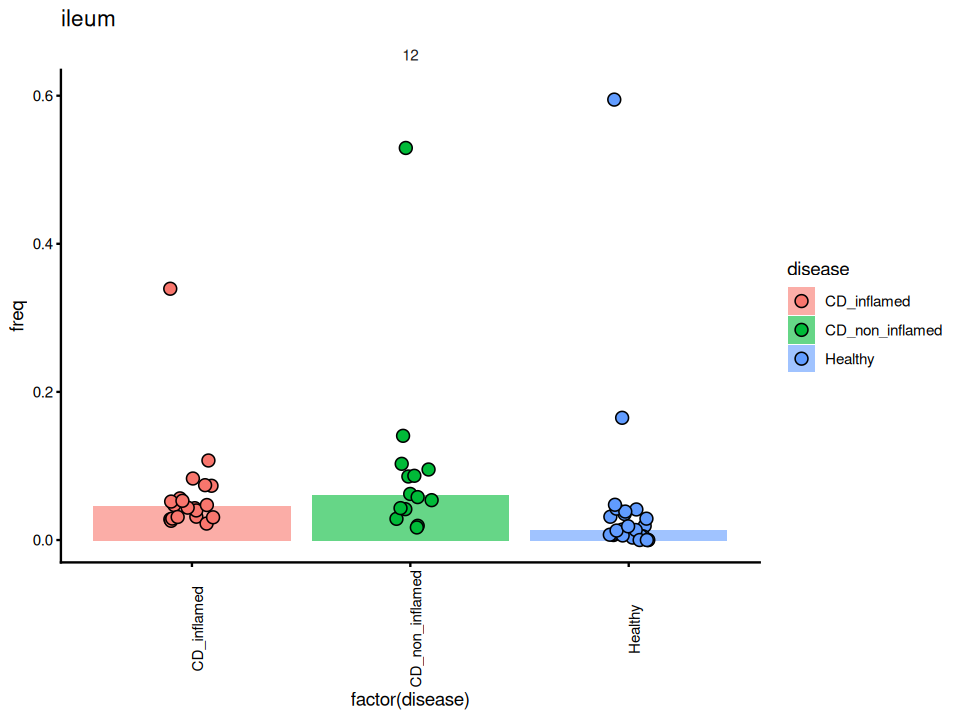

In [83]:
options(repr.plot.width = 8, repr.plot.height = 6)
ileum_cl12 %>% 
unique  %>% 
dplyr::filter(disease != "CD_inflamed/CD_non_inflamed")  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("ileum")

In [81]:
library(scales)

split_y <- trans_new(
  name = "split_y",
  
  transform = function(y) {
    ifelse(
      y <= 0.2,
      y / 0.2 * 0.85,
      0.85 + (y - 0.2) / (0.65 - 0.2) * 0.15
    )
  },
  
  inverse = function(y) {
    ifelse(
      y <= 0.85,
      y / 0.85 * 0.2,
      0.2 + (y - 0.85) / 0.15 * (0.65 - 0.2)
    )
  }
)

Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


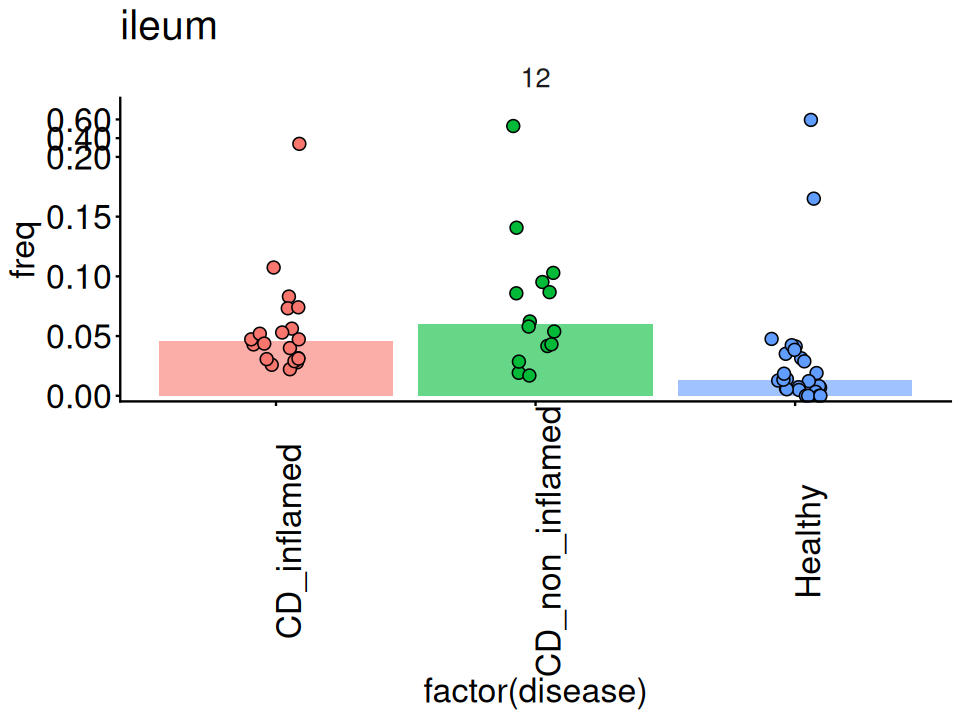

In [85]:
options(repr.plot.width = 8, repr.plot.height = 6)

ileum_cl12 %>% 
  unique() %>% 
  dplyr::filter(disease != "CD_inflamed/CD_non_inflamed") %>% 
  ggplot(aes(x = factor(disease), y = freq)) +
  
  geom_dotplot(
    binaxis = "y", 
    stackdir = "center", 
    dotsize = 0
  ) + 
  
  geom_bar(
    position = "dodge",
    stat = "summary",
    fun = "median",
    alpha = 0.6,
    width = 0.9,
    aes(fill = disease)
  ) +
  
  geom_jitter(
    position = position_jitter(width = 0.1, height = 0),
    size = 3,
    shape = 21,
    aes(fill = disease),
    color = "black"
  ) + 
  
  facet_wrap(
    ~seurat_clusters,
    scales = "free",
    ncol = 1
  ) +
  
  scale_y_continuous(
    trans = split_y,
    limits = c(0, 0.65),
    breaks = c(
      0, 0.05, 0.1, 0.15, 0.2,
       0.4,  0.6
    ),
      expand = expansion(mult = c(0.02, 0.06))
  ) +
  
  theme_classic() +
  theme(
    strip.background = element_blank(),
    panel.grid = element_blank(),
    axis.text.x = element_text(angle = 90)
  ) +
    
  ggtitle("ileum") +
ggtheme() + NoLegend()

ggsave(filename = "figures/vlnplot_scibd_freq_in_ileum.svg",
                  width = 10, height = 18, units = "cm")

In [55]:
ileum_cl12 %>% 
unique  %>% 
dplyr::filter(disease != "CD_inflamed/CD_non_inflamed")  %>% 
ungroup  %>% 
rstatix::kruskal_test(freq~disease)

,.y.,n,statistic,df,p,method
,<chr>,<int>,<dbl>,<int>,<dbl>,<chr>
Kruskal-Wallis chi-squared,freq,60,20.56602,2,3.42e-05,Kruskal-Wallis
